# Ejercicio 9: Redes neuronales dinámicas (red de Hopfield)

**Tópicos Selectos en Aprendizaje Maquinal — TP N°1: Algoritmos para Reconocimiento de Patrones**

En este notebook se implementa una **red recurrente de Hopfield** con entrenamiento **hebbiano** y se la usa como **memoria asociativa** de imágenes binarias.

| Inciso | Consigna | Idea central |
|:--|:--|:--|
| **1** | Arquitectura y entrenamiento hebbiano con los patrones de la Fig. 5 (3 patrones de 5×5) | Los patrones quedan como mínimos de una función de energía |
| **2** | Usar la red como memoria asociativa con los patrones de la Fig. 6 (dígitos 0 a 9 de 7×5) | Capacidad limitada: ¿cuántos dígitos se pueden guardar? |
| **3** | Recuperar los patrones desde versiones ruidosas (inversión de cada píxel con prob. 0.1, 0.2 y 0.5) | Cuenca de atracción y tolerancia al ruido |

**Contenido**

1. [Teoría](#1.-Teoría)
2. [Implementación](#2.-Implementación)
3. [Inciso 1: patrones de la Figura 5](#3.-Inciso-1:-patrones-de-la-Figura-5)
4. [Inciso 2: los dígitos de la Figura 6](#4.-Inciso-2:-los-dígitos-de-la-Figura-6)
5. [Inciso 3: recuperación a partir de patrones ruidosos](#5.-Inciso-3:-recuperación-a-partir-de-patrones-ruidosos)
6. [Conclusiones](#6.-Conclusiones)

---
## 1. Teoría

### 1.1 La red

Una red de Hopfield tiene $N$ neuronas binarias $s_i\in\{-1,+1\}$ completamente conectadas, con **pesos simétricos** $w_{ij}=w_{ji}$ y **sin autoconexiones** ($w_{ii}=0$). No hay entrada ni salida distinguidas: el estado de la red $\mathbf{s}=(s_1,\dots,s_N)$ evoluciona solo, y el "resultado" es el estado al que llega.

En este ejercicio cada neurona es un píxel de la imagen: **negro $=+1$ y blanco $=-1$**.

### 1.2 Dinámica (recuperación)

El campo local de la neurona $i$ es $h_i=\sum_j w_{ij}s_j$ y la regla de actualización es
$$
s_i\leftarrow\operatorname{sign}(h_i)\qquad(\text{si }h_i=0\text{ la neurona conserva su estado}).
$$
Se usa **actualización asincrónica**: en cada paso se actualiza una neurona a la vez, en orden aleatorio, y se repiten *barridos* (un barrido = $N$ actualizaciones) hasta que ningún estado cambia. Con actualización sincrónica (todas a la vez) la red podría oscilar entre dos estados.

### 1.3 Función de energía

Con $\mathbf{W}$ simétrica y de diagonal nula se define
$$
E(\mathbf{s})=-\tfrac12\sum_{i\neq j}w_{ij}s_is_j=-\tfrac12\,\mathbf{s}^\top\mathbf{W}\mathbf{s}.
$$
Si se actualiza la neurona $k$ y cambia de $s_k$ a $s_k'=-s_k$, la energía cambia en
$$
\Delta E=-\big(s_k'-s_k\big)\sum_{j}w_{kj}s_j=-(s_k'-s_k)\,h_k=2s_kh_k<0\quad\text{porque }s_k'=\operatorname{sign}(h_k)=-s_k\Rightarrow s_kh_k<0 .
$$
Es decir, **cada cambio disminuye estrictamente la energía**. Como hay un número finito de estados, la dinámica asincrónica **siempre converge** a un estado estable (un mínimo local de $E$).

### 1.4 Entrenamiento hebbiano

Dados $M$ patrones $\boldsymbol\xi^1,\dots,\boldsymbol\xi^M\in\{-1,+1\}^N$, la regla de Hebb (*"neuronas que se activan juntas se conectan más fuerte"*) es
$$
w_{ij}=\frac1N\sum_{\mu=1}^{M}\xi_i^\mu\xi_j^\mu\quad(i\neq j),\qquad w_{ii}=0 .
$$
Es un entrenamiento de **un solo paso**, sin iteraciones, que produce una matriz simétrica con diagonal nula.

### 1.5 ¿Cuándo un patrón es estable? Ruido cruzado

Si se presenta el patrón $\boldsymbol\xi^\nu$, el campo local de la neurona $i$ es
$$
h_i=\sum_jw_{ij}\xi^\nu_j=\underbrace{\Big(1-\tfrac MN\Big)\xi_i^\nu}_{\text{señal}}+\underbrace{\frac1N\sum_{\mu\neq\nu}\xi_i^\mu\sum_{j}\xi^\mu_j\xi^\nu_j}_{\text{ruido cruzado}} .
$$
El patrón es estable si la señal domina al ruido cruzado en todas las neuronas. El ruido cruzado depende de las **superposiciones** $m_{\mu\nu}=\frac1N\boldsymbol\xi^\mu\!\cdot\!\boldsymbol\xi^\nu$ entre patrones:

- si los patrones son **ortogonales** ($m_{\mu\nu}=0$), no hay ruido cruzado y todos son estables mientras $M<N$;
- si están **correlacionados** (por ejemplo, imágenes con muchos píxeles blancos en común), el ruido cruzado crece y pueden desestabilizarse.

Para patrones aleatorios, la **capacidad** es $M_{\max}\approx0.138\,N$ (resultado de mecánica estadística); con más patrones aparecen estados espurios y la memoria se deteriora. Con patrones correlacionados, la capacidad es **menor**.

### 1.6 Estados espurios

La energía de la red hebbiana es simétrica: $E(-\mathbf{s})=E(\mathbf{s})$. Por lo tanto, **si $\boldsymbol\xi$ es un atractor, también lo es $-\boldsymbol\xi$** (la imagen con los colores invertidos). Además pueden aparecer otros atractores que no son patrones almacenados (mezclas de varios patrones, etc.).

---
## 2. Implementación

Se implementan desde cero la regla de Hebb, la energía, la dinámica asincrónica y algunas utilidades. Las imágenes de la guía (Figs. 5 y 6) se transcribieron como matrices de píxeles (`#` = negro, `.` = blanco).

In [1]:
import itertools
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams.update({"figure.dpi": 110})
pd.set_option("display.width", 200)
rng = np.random.default_rng(2024)


def leer_patron(txt):
    '''Texto con # (negro) y . (blanco) -> matriz de +1/-1.'''
    filas = [f.strip() for f in txt.strip().splitlines()]
    return np.array([[1 if c == "#" else -1 for c in f] for f in filas])


# ----------------- Figura 5: tres patrones de 5x5 -----------------
FIG5 = {
    "A": leer_patron('''
        .....
        .###.
        .#.#.
        .###.
        .....'''),
    "B": leer_patron('''
        ##...
        .##..
        ..#..
        ..##.
        ...##'''),
    "C": leer_patron('''
        #####
        #...#
        #...#
        #...#
        #####'''),
}

# ----------------- Figura 6: dígitos 0-9 de 7x5 -----------------
DIGITOS = {
    0: leer_patron('''
        ..##.
        .#..#
        .#..#
        .#..#
        .#..#
        .#..#
        ..##.'''),
    1: leer_patron('''
        ..#..
        .##..
        ..#..
        ..#..
        ..#..
        ..#..
        .###.'''),
    2: leer_patron('''
        .###.
        #...#
        ....#
        .###.
        #....
        #....
        .####'''),
    3: leer_patron('''
        .###.
        #...#
        ....#
        .###.
        ....#
        #...#
        .###.'''),
    4: leer_patron('''
        ...#.
        ..##.
        .#.#.
        #..#.
        #####
        ...#.
        ...#.'''),
    5: leer_patron('''
        #####
        #....
        ####.
        ....#
        ....#
        #...#
        .###.'''),
    6: leer_patron('''
        ..##.
        .#...
        #....
        ####.
        #...#
        #...#
        .###.'''),
    7: leer_patron('''
        #####
        ....#
        ...#.
        ..#..
        .#...
        .#...
        .#...'''),
    8: leer_patron('''
        .###.
        #...#
        #...#
        .###.
        #...#
        #...#
        .###.'''),
    9: leer_patron('''
        .###.
        #...#
        #...#
        .####
        ....#
        ...#.
        .##..'''),
}


# ----------------- Red de Hopfield -----------------
def entrenar_hebb(X):
    '''Regla de Hebb. X: (M, N) con patrones ±1 en las filas.'''
    N = X.shape[1]
    W = X.T @ X / N
    np.fill_diagonal(W, 0.0)
    return W


def energia(W, s):
    return -0.5 * s @ W @ s


def es_estable(W, s):
    '''Un estado es estable si ninguna neurona quiere cambiar (h_i = 0 conserva el estado).'''
    return bool(np.all(s * (W @ s) >= -1e-12))


def recuperar(W, s0, rng, max_barridos=100, con_energia=False):
    '''Dinámica asincrónica. Devuelve (estado final, barridos hasta converger, trayectoria de energía).'''
    s = s0.astype(float).copy(); N = len(s)
    E = [energia(W, s)] if con_energia else None
    for b in range(max_barridos):
        hubo_cambio = False
        for i in rng.permutation(N):
            h = W[i] @ s
            if h * s[i] < -1e-12:          # el campo local contradice al estado
                s[i] = -s[i]; hubo_cambio = True
                if con_energia:
                    E.append(energia(W, s))
        if not hubo_cambio:
            return s, b, E
    return s, max_barridos, E


def identificar(s, X, nombres):
    '''Nombre del patrón almacenado (o "−nombre" si es su inverso) al que es igual el estado s; None si es espurio.'''
    for k, x in zip(nombres, X):
        if np.array_equal(s, x): return f"{k}"
        if np.array_equal(s, -x): return f"−{k}"
    return None


def ruido(s, p, rng):
    '''Invierte cada píxel con probabilidad p.'''
    s = s.copy(); s[rng.random(len(s)) < p] *= -1
    return s


# ----------------- Visualización -----------------
def dibujar(ax, s, forma, titulo="", color_borde=None, fs=8):
    img = ((np.asarray(s).reshape(forma) + 1) / 2)       # negro = 1
    ax.imshow(img, cmap="gray_r", vmin=0, vmax=1)
    ax.set_xticks(np.arange(-0.5, forma[1], 1), minor=True); ax.set_yticks(np.arange(-0.5, forma[0], 1), minor=True)
    ax.grid(which="minor", color="gray", lw=0.5); ax.grid(which="major", visible=False)
    ax.tick_params(which="both", length=0, labelbottom=False, labelleft=False)
    if color_borde:
        for sp in ax.spines.values():
            sp.set_edgecolor(color_borde); sp.set_linewidth(2.5)
    ax.set_title(titulo, fontsize=fs)

---
## 3. Inciso 1: patrones de la Figura 5

La Figura 5 muestra tres patrones de $5\times5$ píxeles, es decir, una red de **$N=25$ neuronas** con **$M=3$ patrones** a almacenar. La relación $M/N=0.12$ está cerca del límite teórico $0.138$.

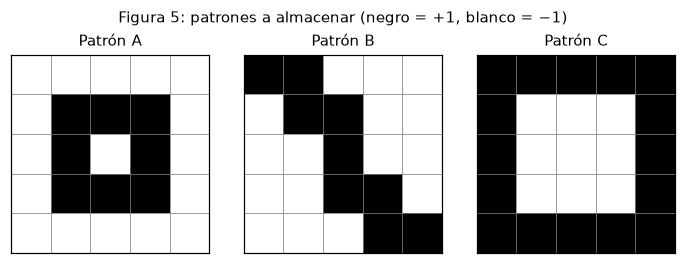

Píxeles negros por patrón: {'A': 8, 'B': 9, 'C': 16}  de 25


In [2]:
forma5 = (5, 5)
X5 = np.array([p.ravel() for p in FIG5.values()]); nombres5 = list(FIG5)
fig, axs = plt.subplots(1, 3, figsize=(6.5, 2.4))
for ax, (k, p) in zip(axs, FIG5.items()):
    dibujar(ax, p, forma5, f"Patrón {k}", fs=10)
plt.suptitle("Figura 5: patrones a almacenar (negro = +1, blanco = −1)", fontsize=10); plt.tight_layout(); plt.show()
print("Píxeles negros por patrón:", {k: int(v) for k, v in zip(nombres5, (X5 > 0).sum(1))}, " de", X5.shape[1])

### 3.1 Arquitectura y entrenamiento hebbiano

La red tiene 25 neuronas y una matriz de pesos $\mathbf{W}$ de $25\times25$, simétrica y de diagonal nula, obtenida en un solo paso con
$w_{ij}=\frac1{25}\sum_{\mu=1}^3\xi_i^\mu\xi_j^\mu$.

W simétrica: True    diagonal nula: True    valores distintos de w_ij (×25): [-3, -1, 0, 1, 3]

Superposiciones m_μν = ξ^μ·ξ^ν / N entre los patrones:


,A,B,C
A,1.00,0.28,-0.92
B,0.28,1.00,-0.36
C,-0.92,-0.36,1.00


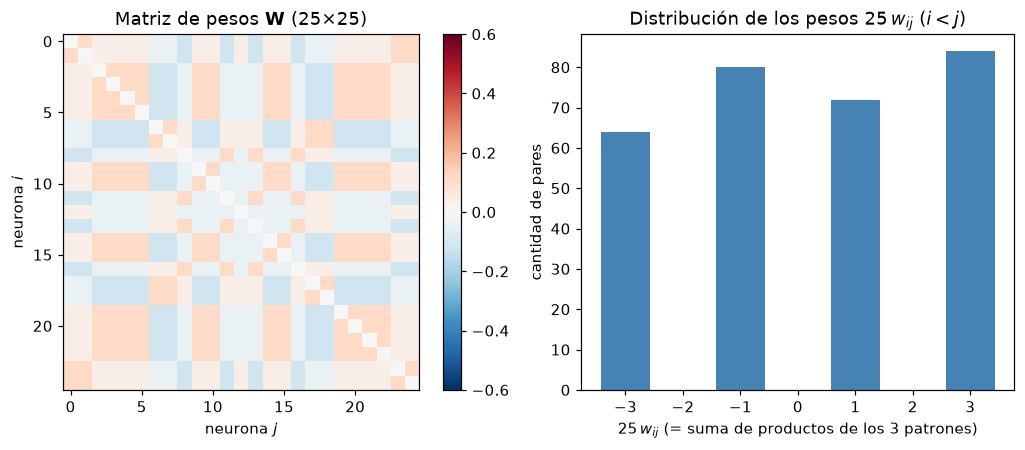

In [3]:
W5 = entrenar_hebb(X5)
print("W simétrica:", np.allclose(W5, W5.T), "   diagonal nula:", np.allclose(np.diag(W5), 0),
      "   valores distintos de w_ij (×25):", sorted(int(v) for v in set(np.round(W5 * 25).astype(int).ravel())))

M5 = X5 @ X5.T / X5.shape[1]
print("\nSuperposiciones m_μν = ξ^μ·ξ^ν / N entre los patrones:")
display(pd.DataFrame(M5, index=nombres5, columns=nombres5).round(2))

fig, axs = plt.subplots(1, 2, figsize=(10, 4.2), gridspec_kw={"width_ratios": [1.1, 1]})
im = axs[0].imshow(W5, cmap="RdBu_r", vmin=-0.6, vmax=0.6); plt.colorbar(im, ax=axs[0], fraction=0.046)
axs[0].set(title="Matriz de pesos $\\mathbf{W}$ (25×25)", xlabel="neurona $j$", ylabel="neurona $i$")
axs[1].hist(W5[np.triu_indices(25, 1)] * 25, bins=np.arange(-3.5, 4.5, 1), rwidth=0.85, color="steelblue")
axs[1].set(title="Distribución de los pesos $25\\,w_{ij}$ ($i<j$)", xlabel="$25\\,w_{ij}$ (= suma de productos de los 3 patrones)", ylabel="cantidad de pares")
plt.tight_layout(); plt.show()

**Observaciones.**

- **Los patrones A y C están casi en oposición:** su superposición es $m_{AC}=-0.92$. De hecho, **A difiere de $-C$ en un solo píxel** (el píxel central): $C$ es un marco negro con el interior blanco, $-C$ es un marco blanco con el interior negro, y $A$ es ese interior negro con un agujero blanco en el centro. Para la red hebbiana, $A$ y $-C$ son casi la misma memoria. El patrón $B$ tiene superposiciones moderadas con los otros dos ($0.28$ con $A$ y $-0.36$ con $C$).
- **Pesos:** fuera de la diagonal, $25\,w_{ij}$ es la suma de tres productos $\pm1$, así que solo puede valer $\pm1$ o $\pm3$ (el $0$ de la lista corresponde a la diagonal). La matriz es simétrica y de diagonal nula, como exige el modelo.

### 3.2 ¿Son estables los patrones almacenados?

Se verifica con la definición (ninguna neurona cambia al actualizar), y se calcula el campo local $h_i$ y la energía de cada patrón.

In [4]:
filas = []
for k, x in zip(nombres5, X5):
    h = W5 @ x
    sf, _, _ = recuperar(W5, x, rng)
    filas.append({"Patrón": k, "¿estable?": es_estable(W5, x), "mín. de ξ_i·h_i": (x * h).min(),
                  "píxeles inestables": int((x * h < -1e-12).sum()), "E(ξ)": energia(W5, x), "E(−ξ)": energia(W5, -x),
                  "salida desde el patrón limpio": identificar(sf, X5, nombres5) or "espurio"})
display(pd.DataFrame(filas).round(3))

hA = X5[0] * (W5 @ X5[0])
r_, c_ = divmod(int(np.argmin(hA)), 5)
print(f"Píxel inestable del patrón A: fila {r_}, columna {c_} (contando desde 0);  píxeles en que A difiere de −C: {int((X5[0] != -X5[2]).sum())}")

print("\nEstabilidad al almacenar solo pares de patrones:")
for (i, a), (j, b) in itertools.combinations(list(enumerate(nombres5)), 2):
    Wp = entrenar_hebb(X5[[i, j]])
    print(f"  {{{a},{b}}}:  {a} estable = {es_estable(Wp, X5[i])},  {b} estable = {es_estable(Wp, X5[j])}")

,Patrón,¿estable?,mín. de ξ_i·h_i,píxeles inestables,E(ξ),E(−ξ),salida desde el patrón limpio
0,A,False,-0.32,1,-22.56,-22.56,−C
1,B,True,0.24,0,-13.60,-13.60,B
2,C,True,0.32,0,-23.20,-23.20,C


Píxel inestable del patrón A: fila 2, columna 2 (contando desde 0);  píxeles en que A difiere de −C: 1

Estabilidad al almacenar solo pares de patrones:
  {A,B}:  A estable = True,  B estable = True
  {A,C}:  A estable = True,  C estable = True
  {B,C}:  B estable = True,  C estable = True


**Observaciones.**

- **$B$ y $C$ son estables** (en todas sus neuronas el campo local refuerza el estado: $\xi_ih_i>0$).
- **$A$ NO es estable:** hay un píxel (fila 2, columna 2, el central) cuyo campo local contradice al patrón. Si se deja evolucionar la red desde $A$ limpio, **termina en $-C$**, es decir, la red "corrige" el agujero del centro y convierte $A$ en el inverso de $C$. En la sección 3.3 se confirma que $A$ no es un atractor.
- **No es un problema de cantidad:** $M/N=3/25=0.12<0.138$. Es consecuencia de la correlación entre patrones ($m_{AC}=-0.92$ da un ruido cruzado grande). De hecho, $A$ y $C$ almacenados **solos** (sin $B$) sí son ambos estables, igual que los otros dos pares; al agregar el tercer patrón, el píxel central de $A$ deja de serlo.
- **Simetría de la energía:** $E(\xi)=E(-\xi)$ en los tres patrones, como se anticipó en la teoría. $C$ tiene la energía más baja ($-23.20$), seguido por $A$ ($-22.56$) y $B$ ($-13.60$).

### 3.3 Todos los puntos fijos de la red (búsqueda exhaustiva)

Con $N=25$ hay $2^{25}\approx3.4\times10^7$ estados posibles. Es factible revisarlos **todos** para encontrar los estados estables de la red (los atractores). Se usan pesos enteros ($25\,\mathbf{W}$) para que no haya errores de redondeo en los empates $h_i=0$.

In [5]:
def puntos_fijos_exhaustivo(W_entera, chunk=1 << 19):
    '''Todos los estados s ∈ {±1}^N con s_i·h_i >= 0 para todo i (N <= ~25).'''
    N = W_entera.shape[0]; pot = np.arange(N, dtype=np.uint32); out = []
    for a in range(0, 1 << N, chunk):
        idx = np.arange(a, min(a + chunk, 1 << N), dtype=np.uint32)
        s = ((idx[:, None] >> pot) & 1).astype(np.float32) * 2 - 1
        ok = (s * (s @ W_entera) >= 0).all(axis=1)
        out.append(s[ok].astype(np.int8))
    return np.vstack(out)


W5_ent = np.round(W5 * 25).astype(np.float32)
F5 = puntos_fijos_exhaustivo(W5_ent)
print(f"Estados estables encontrados: {len(F5)} de {2**25:,}")

etiq = [identificar(s, X5, nombres5) for s in F5]
almac = [e for e in etiq if e is not None]
esp = [s for s, e in zip(F5, etiq) if e is None]
print("Patrones almacenados (y sus inversos) entre los puntos fijos:", sorted(almac))
print(f"Estados espurios (ni un patrón ni su inverso): {len(esp)}")

Estados estables encontrados: 4 de 33,554,432
Patrones almacenados (y sus inversos) entre los puntos fijos: ['B', 'C', '−B', '−C']
Estados espurios (ni un patrón ni su inverso): 0


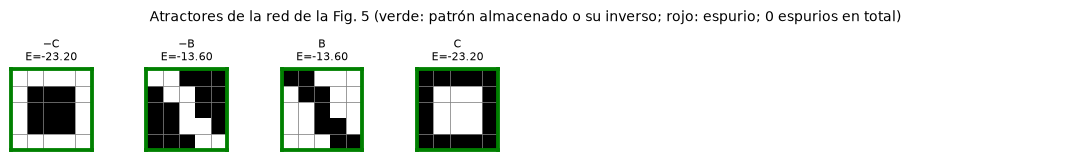

In [6]:
# Los puntos fijos que NO son patrones almacenados, ordenados por energía
esp_ord = sorted(esp, key=lambda s: energia(W5, s.astype(float)))
n_mostrar = min(len(esp_ord), 24)
cols = 8; filas_g = int(np.ceil((6 + n_mostrar) / cols))
fig, axs = plt.subplots(filas_g, cols, figsize=(cols * 1.25, filas_g * 1.45))
axs = np.atleast_2d(axs).ravel()
for ax in axs: ax.axis("off")
todos = [(f"{e}\nE={energia(W5, s.astype(float)):.2f}", s, "green") for s, e in zip(F5, etiq) if e is not None] + \
        [(f"espurio\nE={energia(W5, s.astype(float)):.2f}", s, "tab:red") for s in esp_ord[:n_mostrar]]
for ax, (t, s, c) in zip(axs, todos):
    ax.axis("on"); dibujar(ax, s, forma5, t, color_borde=c, fs=7)
plt.suptitle(f"Atractores de la red de la Fig. 5 (verde: patrón almacenado o su inverso; rojo: espurio; {len(esp)} espurios en total)", fontsize=9)
plt.tight_layout(); plt.show()

**Observaciones.**

- De los **33 554 432** estados posibles, **solo 4 son estables: $B$, $-B$, $C$ y $-C$**. No hay ningún estado espurio (las figuras muestran únicamente atractores almacenados o sus inversos).
- Por lo tanto, el patrón $A$ no es una memoria de la red: de los tres patrones se almacenaron efectivamente **dos** (más sus inversos). Cualquier otro estado, incluido $A$, termina al evolucionar en uno de estos cuatro.
- La energía del patrón $C$ ($-23.2$) es mucho menor que la de $B$ ($-13.6$): el mínimo de $C$ es "más profundo".

### 3.4 Cuencas de atracción: dinámica desde estados iniciales aleatorios y desde patrones degradados

**(i) Desde estados completamente aleatorios.** Se parte de 5000 estados aleatorios y se registra el atractor al que llega la red.

In [7]:
T = 5000
destino = {}
for _ in range(T):
    s0 = rng.choice([-1.0, 1.0], size=25)
    sf, b, _ = recuperar(W5, s0, rng)
    e = identificar(sf, X5, nombres5) or "espurio"; destino[e] = destino.get(e, 0) + 1
print("Atractor alcanzado desde estados aleatorios:")
display(pd.Series(destino).sort_index().to_frame("cantidad").assign(porcentaje=lambda d: (100 * d["cantidad"] / T).round(1)).T)

Atractor alcanzado desde estados aleatorios:


,B,C,−B,−C
cantidad,444.0,2095.0,414.0,2047.0
porcentaje,8.9,41.9,8.3,40.9


**(ii) Desde cada patrón degradado** (inversión de cada píxel con probabilidad $p$) y evolución de la **energía** en una corrida.

Fracción de corridas en que la red recupera exactamente el patrón (300 corridas por celda):


,A,B,C
p=0.0,0.0,1.00,1.00
p=0.1,0.0,0.86,1.00
p=0.2,0.0,0.64,1.00
p=0.3,0.0,0.44,0.97
p=0.4,0.0,0.24,0.76
p=0.5,0.0,0.08,0.42


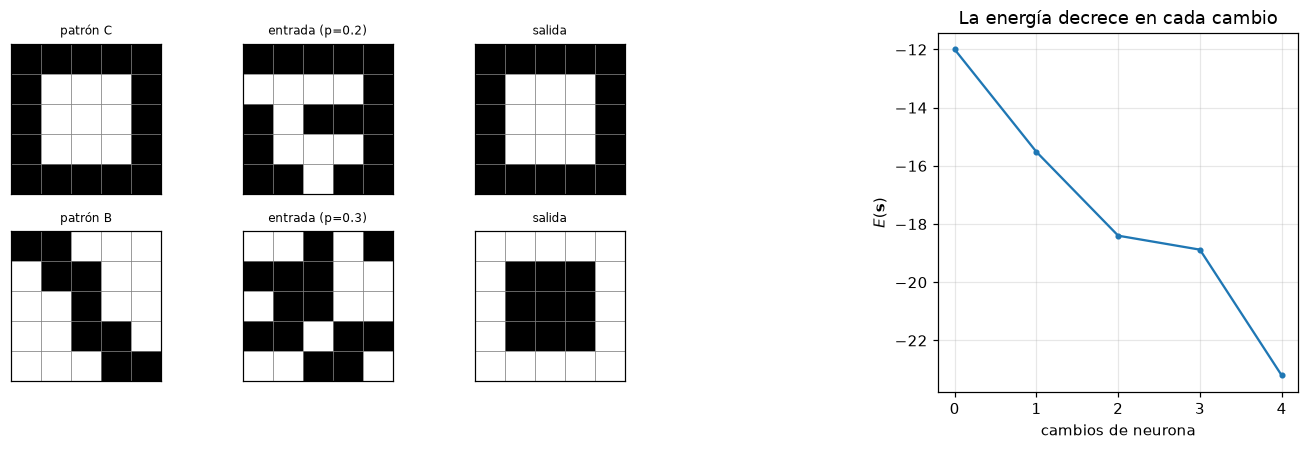

¿La energía fue monótonamente decreciente? True


In [8]:
ps = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5]
TR = 300
tabla = pd.DataFrame(index=[f"p={p}" for p in ps], columns=nombres5, dtype=float)
for p in ps:
    for k, x in zip(nombres5, X5):
        ok = 0
        for _ in range(TR):
            sf, _, _ = recuperar(W5, ruido(x, p, rng), rng); ok += np.array_equal(sf, x)
        tabla.loc[f"p={p}", k] = ok / TR
print(f"Fracción de corridas en que la red recupera exactamente el patrón ({TR} corridas por celda):")
display(tabla.round(2))

# Trayectorias de energía y ejemplos de recuperación
fig = plt.figure(figsize=(12, 4.2))
gs = fig.add_gridspec(2, 5, width_ratios=[1, 1, 1, 1, 2.4])
x = X5[2]  # patrón C
s0 = ruido(x, 0.2, rng)
sf, nb, E = recuperar(W5, s0, rng, con_energia=True)
for j, (t, s) in enumerate([("patrón C", x), ("entrada (p=0.2)", s0), ("salida", sf)]):
    dibujar(fig.add_subplot(gs[0, j]), s, forma5, t)
ax = fig.add_subplot(gs[:, 4]); ax.plot(E, "o-", ms=3); ax.set(xlabel="cambios de neurona", ylabel="$E(\\mathbf{s})$", title="La energía decrece en cada cambio"); ax.grid(alpha=0.3)
x = X5[1]; s0 = ruido(x, 0.3, rng); sf, _, _ = recuperar(W5, s0, rng)
for j, (t, s) in enumerate([("patrón B", x), ("entrada (p=0.3)", s0), ("salida", sf)]):
    dibujar(fig.add_subplot(gs[1, j]), s, forma5, t)
plt.tight_layout(); plt.show()
print("¿La energía fue monótonamente decreciente?", bool(np.all(np.diff(E) < 0)))

**Observaciones.**

- **Desde estados aleatorios** la red siempre termina en uno de los 4 atractores: $C$ (41.9 %), $-C$ (40.9 %), $B$ (8.9 %) y $-B$ (8.3 %). El tamaño de la cuenca de atracción acompaña a la profundidad del mínimo de energía: $C$ y $-C$, los más profundos, captan en conjunto el 83 % de los estados. Los pares $\pm$ tienen cuencas casi iguales, como corresponde por simetría.
- **Desde patrones degradados**, $C$ es muy robusto (100 % con $p\le0.2$, 97 % con $p=0.3$) y $B$ lo es menos (86 %, 64 % y 44 % con $p=0.1$, $0.2$ y $0.3$). El patrón $A$ no se recupera **nunca** (0 %), porque no es un punto fijo.
- Con $p=0.5$ la entrada no contiene ninguna información del patrón (es un estado al azar) y se obtienen los mismos porcentajes que partiendo de estados aleatorios: 42 % para $C$ y 8 % para $B$, que coinciden con los de la cuenca (41.9 % y 8.9 %).
- **Energía:** en la corrida mostrada decrece en cada cambio de neurona (se verificó que sea monótona) hasta llegar al mínimo, como asegura la demostración de la teoría. El ejemplo de $B$ con $p=0.3$ muestra que, con mucho ruido, la red puede terminar en otro atractor (aquí $-C$).

---
## 4. Inciso 2: los dígitos de la Figura 6

La Figura 6 muestra los dígitos 0 a 9 como imágenes de $7\times5=35$ píxeles, es decir, una red de **$N=35$ neuronas**. Se quiere usar la red como **memoria asociativa**: almacenar los 10 dígitos y, dado un dígito (posiblemente degradado), recuperar la memoria completa.

Ya se puede anticipar un problema: la capacidad teórica es $0.138\times35\approx4.8$ patrones, y se piden **10**.

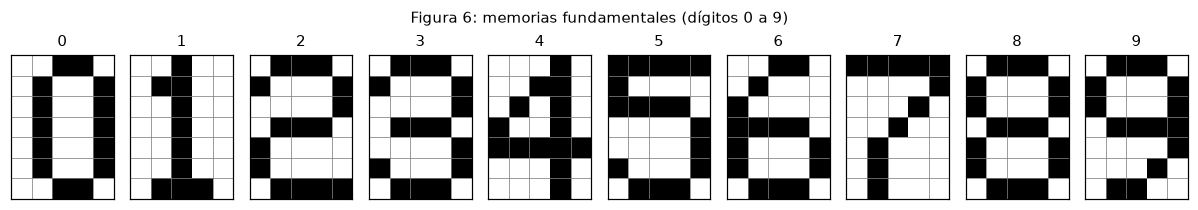

In [9]:
forma6 = (7, 5)
X6 = np.array([DIGITOS[d].ravel() for d in range(10)])
fig, axs = plt.subplots(1, 10, figsize=(11, 1.9))
for d, ax in enumerate(axs):
    dibujar(ax, X6[d], forma6, str(d), fs=10)
plt.suptitle("Figura 6: memorias fundamentales (dígitos 0 a 9)", fontsize=10); plt.tight_layout(); plt.show()

### 4.1 Almacenar los 10 dígitos con la regla de Hebb

Se calcula la matriz de superposiciones entre dígitos (que determina el ruido cruzado) y se verifica la estabilidad de cada dígito.

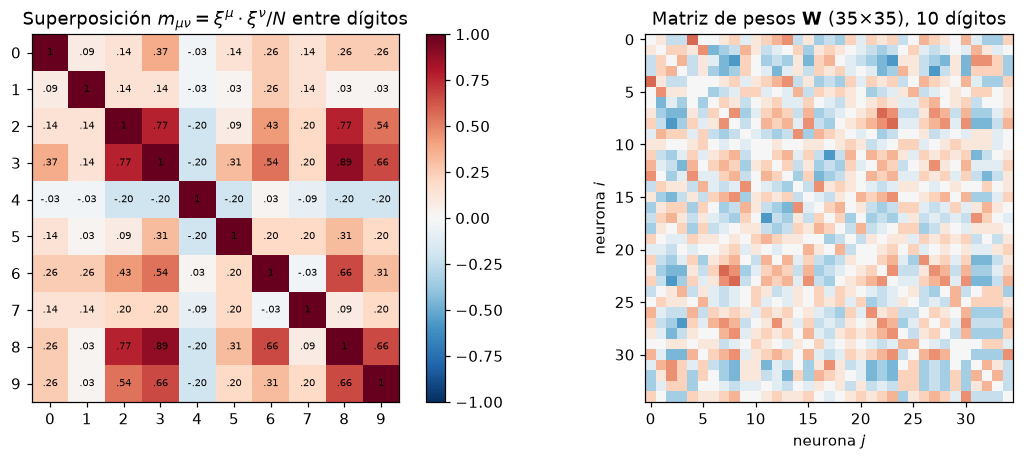

Superposición media entre dígitos distintos: 0.211  (máxima: 0.89;  para patrones aleatorios sería ≈ 0 ± 0.17)
Par más parecido: dígitos 3 y 8  (superposición 0.89, difieren en 2 píxeles de 35)


In [10]:
W6 = entrenar_hebb(X6)
M6 = X6 @ X6.T / 35

fig, axs = plt.subplots(1, 2, figsize=(11.5, 4.3), gridspec_kw={"width_ratios": [1, 1.15]})
im = axs[0].imshow(M6, cmap="RdBu_r", vmin=-1, vmax=1)
for i in range(10):
    for j in range(10):
        axs[0].text(j, i, f"{M6[i, j]:.2f}".replace("0.", ".").replace("1.00", "1"), ha="center", va="center", fontsize=6.5)
axs[0].set(xticks=range(10), yticks=range(10), title="Superposición $m_{\\mu\\nu}=\\xi^\\mu\\cdot\\xi^\\nu/N$ entre dígitos")
axs[0].grid(False); plt.colorbar(im, ax=axs[0], fraction=0.046)
axs[1].imshow(W6, cmap="RdBu_r", vmin=-0.5, vmax=0.5); axs[1].grid(False)
axs[1].set(title="Matriz de pesos $\\mathbf{W}$ (35×35), 10 dígitos", xlabel="neurona $j$", ylabel="neurona $i$")
plt.tight_layout(); plt.show()

fuera = M6[np.triu_indices(10, 1)]
print(f"Superposición media entre dígitos distintos: {fuera.mean():.3f}  (máxima: {fuera.max():.2f};  para patrones aleatorios sería ≈ 0 ± {1/np.sqrt(35):.2f})")
i, j = np.unravel_index(np.argmax(np.where(np.eye(10) > 0, -1, M6)), M6.shape)
print(f"Par más parecido: dígitos {i} y {j}  (superposición {M6[i, j]:.2f}, difieren en {int((X6[i] != X6[j]).sum())} píxeles de 35)")

,Dígito,¿estable?,píxeles inestables,salida (desde el dígito limpio),píxeles distintos al original
0,0,False,9,espurio,12
1,1,False,5,espurio,16
2,2,False,5,espurio,5
3,3,False,1,espurio,1
4,4,False,5,espurio,13
5,5,False,9,espurio,11
6,6,False,6,espurio,7
7,7,False,4,espurio,15
8,8,False,1,espurio,1
9,9,False,5,espurio,5


Dígitos estables: 0 de 10
Estados finales distintos alcanzados desde los 10 dígitos limpios: 2 → dígitos que llegan a cada uno: [[0, 1, 2, 3, 5, 6, 7, 8, 9], [4]]


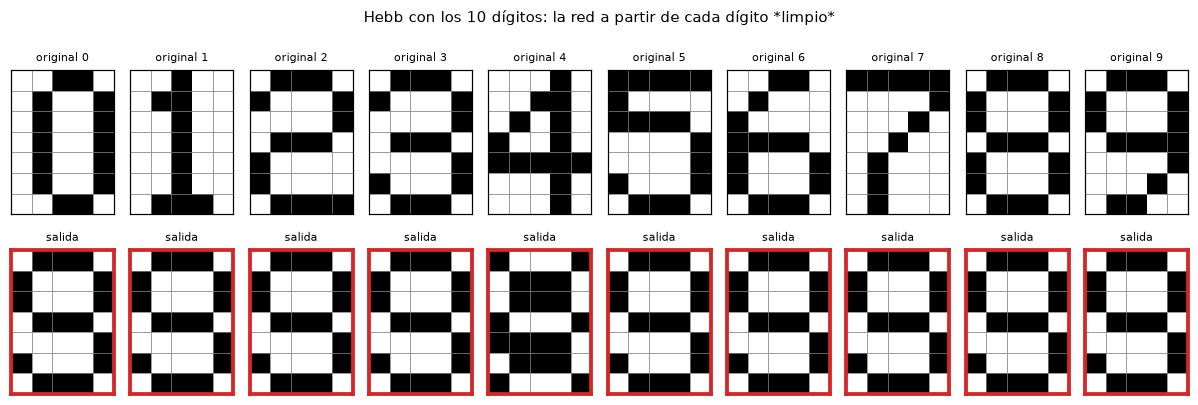

In [11]:
filas = []
salidas6 = []
for d in range(10):
    x = X6[d]; h = W6 @ x
    sf, nb, _ = recuperar(W6, x, rng)
    salidas6.append(sf)
    filas.append({"Dígito": d, "¿estable?": es_estable(W6, x), "píxeles inestables": int((x * h < -1e-12).sum()),
                  "salida (desde el dígito limpio)": identificar(sf, X6, [str(k) for k in range(10)]) or "espurio",
                  "píxeles distintos al original": int((sf != x).sum())})
tab6 = pd.DataFrame(filas)
display(tab6)
print("Dígitos estables:", int(tab6["¿estable?"].sum()), "de 10")
from collections import Counter
cnt_fin = Counter(tuple(s_.astype(int)) for s_ in salidas6)
print("Estados finales distintos alcanzados desde los 10 dígitos limpios:", len(cnt_fin), "→ dígitos que llegan a cada uno:",
      [[d for d in range(10) if tuple(salidas6[d].astype(int)) == k] for k in cnt_fin])

fig, axs = plt.subplots(2, 10, figsize=(11, 3.9))
for d in range(10):
    dibujar(axs[0, d], X6[d], forma6, f"original {d}", fs=7)
    dibujar(axs[1, d], salidas6[d], forma6, "salida", color_borde="green" if np.array_equal(salidas6[d], X6[d]) else "tab:red", fs=7)
plt.suptitle("Hebb con los 10 dígitos: la red a partir de cada dígito *limpio*", fontsize=10); plt.tight_layout(); plt.show()

**Observaciones.**

- **Con los 10 dígitos, la regla de Hebb falla por completo: ningún dígito es estable** (cada uno tiene entre 1 y 9 píxeles inestables).
- **Los dígitos están muy correlacionados:** la superposición media entre dígitos distintos es $0.21$ (para patrones aleatorios sería $\approx0$, con dispersión $0.17$) y hay pares muy parecidos: **3 y 8 difieren en solo 2 píxeles** ($m=0.89$), y también $2$-$3$, $2$-$8$ ($0.77$) o $3$-$9$, $6$-$8$, $8$-$9$ ($0.66$). Los dígitos 0, 2, 3, 5, 6, 8 y 9 comparten gran parte de su contorno. El 4 es el más "distinto" (superposición $\le0.03$ con todos y negativa con 8 de los 9 dígitos restantes), pero igual es inestable.
- **Además se excede la capacidad:** $M/N=10/35\approx0.29$, el doble del límite teórico para patrones aleatorios ($0.138$), que para patrones correlacionados es todavía menor.
- **La memoria es inútil con esta carga:** desde los 10 dígitos limpios la red llega solo a **dos estados espurios**: uno al que van a parar los dígitos 0, 1, 2, 3, 5, 6, 7, 8 y 9 (una mezcla de ellos, parecida a un 8/0) y otro al que va el 4. No se recupera ninguno.

### 4.2 ¿Cuántos dígitos se pueden almacenar? Capacidad de la red

**(i) Subconjuntos aleatorios.** Para cada tamaño $m$ se eligen al azar 300 subconjuntos de $m$ dígitos y se mide la fracción de dígitos almacenados que resultan estables.

**(ii) Búsqueda exhaustiva.** Hay solo $2^{10}-1=1023$ subconjuntos posibles de dígitos, así que se pueden probar todos y contar cuántos tienen **todos** sus dígitos estables.

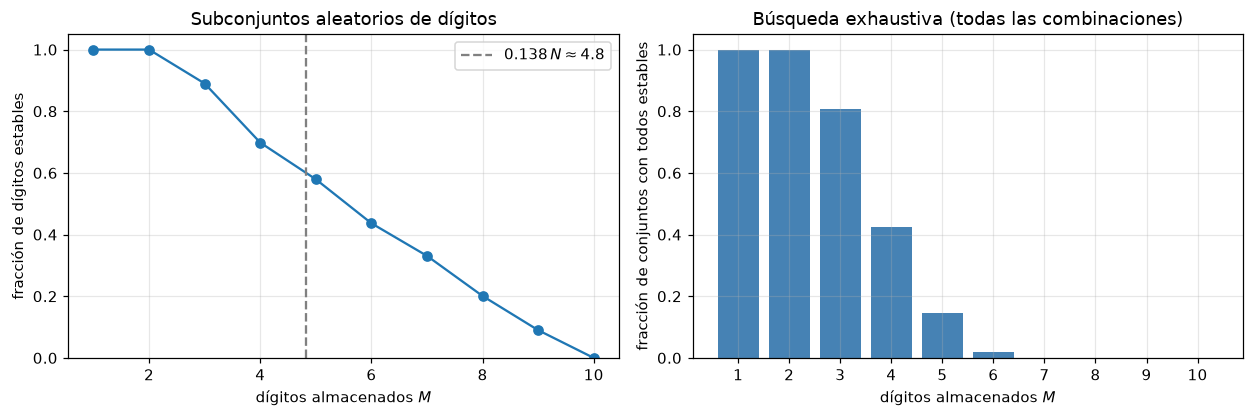

Fracción de dígitos estables (subconjuntos aleatorios): {1: 1.0, 2: 1.0, 3: 0.89, 4: 0.7, 5: 0.58, 6: 0.44, 7: 0.33, 8: 0.2, 9: 0.09, 10: 0.0}


,1,2,3,4,5,6,7,8,9,10
conjuntos posibles,10,45,120,210,252,210,120,45,10,1
con todos los dígitos estables,10,45,97,89,37,4,0,0,0,0


Conjuntos de 6 dígitos totalmente estables: [(0, 1, 2, 4, 5, 7), (0, 1, 4, 5, 6, 7), (0, 2, 4, 5, 6, 7), (1, 2, 4, 5, 6, 7)]


In [12]:
def fraccion_estable(Xs):
    Ws = entrenar_hebb(Xs)
    return np.mean([es_estable(Ws, x) for x in Xs])


ms = np.arange(1, 11)
frac = [np.mean([fraccion_estable(X6[rng.choice(10, m, replace=False)]) for _ in range(300)]) for m in ms]

# exhaustivo
buenos = {m: [] for m in ms}; total = {m: 0 for m in ms}
for m in ms:
    for sub in itertools.combinations(range(10), m):
        total[m] += 1
        if fraccion_estable(X6[list(sub)]) == 1.0:
            buenos[m].append(sub)

fig, axs = plt.subplots(1, 2, figsize=(11.5, 3.9))
axs[0].plot(ms, frac, "o-"); axs[0].axvline(0.138 * 35, color="gray", ls="--", label="$0.138\\,N\\approx4.8$")
axs[0].set(xlabel="dígitos almacenados $M$", ylabel="fracción de dígitos estables", title="Subconjuntos aleatorios de dígitos", ylim=(0, 1.05)); axs[0].legend(); axs[0].grid(alpha=0.3)
axs[1].bar(ms, [len(buenos[m]) / total[m] for m in ms], color="steelblue")
axs[1].set(xlabel="dígitos almacenados $M$", ylabel="fracción de conjuntos con todos estables", title="Búsqueda exhaustiva (todas las combinaciones)", ylim=(0, 1.05)); axs[1].set_xticks(ms); axs[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

print("Fracción de dígitos estables (subconjuntos aleatorios):", {int(m): round(float(f), 2) for m, f in zip(ms, frac)})
display(pd.DataFrame({"conjuntos posibles": total, "con todos los dígitos estables": {m: len(buenos[m]) for m in ms}}).T)
print("Conjuntos de 6 dígitos totalmente estables:", buenos[6])

**Observaciones.**

- **Subconjuntos aleatorios:** la fracción de dígitos estables es $1$ para $M\le2$ y baja a $0.89$ ($M=3$), $0.70$ ($M=4$), $0.58$ ($M=5$), $0.44$ ($M=6$), $0.20$ ($M=8$) y $0$ para $M=10$. Cerca del límite teórico ($0.138N\approx4.8$) la red ya falla en una parte de los dígitos.
- **Búsqueda exhaustiva:** todos los conjuntos de 1 o 2 dígitos son estables; con 3 dígitos lo son 97 de 120 (81 %), con 4 dígitos 89 de 210 (42 %), con 5 dígitos 37 de 252 (15 %) y con 6 dígitos solo **4 de 210** (1.9 %). **Con 7 o más dígitos no existe ningún conjunto cuyos dígitos sean todos estables:** el máximo que se puede almacenar con la regla de Hebb es **6 dígitos**.
- **Qué tienen en común los 4 conjuntos máximos:** los cuatro incluyen los dígitos 4, 5 y 7, completan con 3 de entre $\{0,1,2,6\}$, y **ninguno contiene 3, 8 ni 9**, que son justamente los más parecidos entre sí en la matriz de superposiciones. Es decir, la capacidad efectiva depende de **cuáles** patrones se almacenan, no solo de cuántos.

### 4.3 Memoria asociativa con un conjunto que sí se puede almacenar

Se adopta uno de los conjuntos máximos hallados en la búsqueda exhaustiva: **los dígitos 0, 1, 2, 4, 5 y 7** (el primero de los conjuntos de 6 dígitos). Se verifica que cada dígito sea estable y que la red los recupere a partir de una versión degradada.

Dígitos almacenados: [0, 1, 2, 4, 5, 7]
¿Todos estables? True


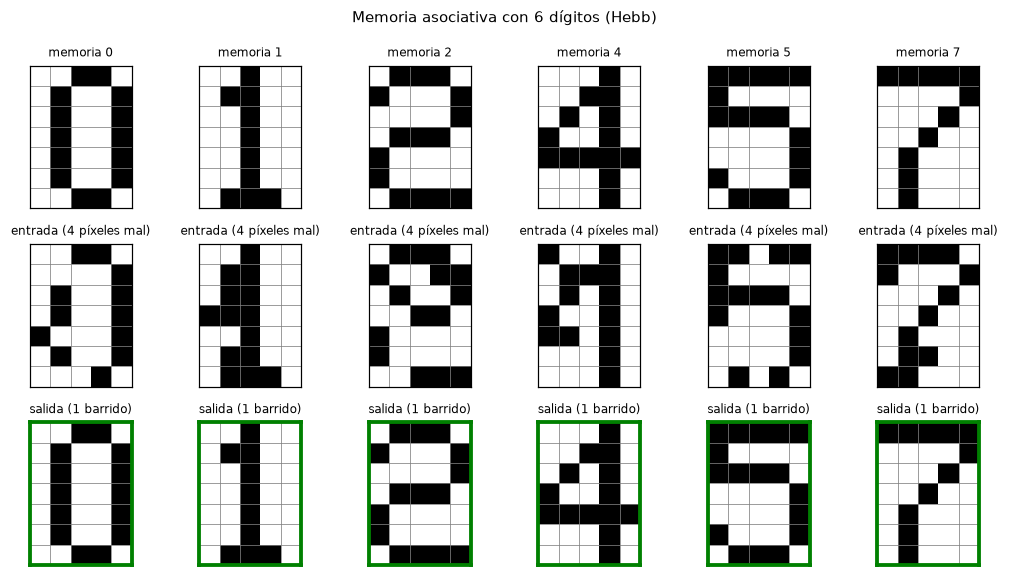

In [13]:
MEM = list(buenos[6][0]); print("Dígitos almacenados:", MEM)
X_mem = X6[MEM]; W_mem = entrenar_hebb(X_mem)
print("¿Todos estables?", all(es_estable(W_mem, x) for x in X_mem))

# ejemplo: cada dígito de la memoria desde una versión con 4 píxeles invertidos
fig, axs = plt.subplots(3, len(MEM), figsize=(1.6 * len(MEM), 5.3))
for j, d in enumerate(MEM):
    s0 = X6[d].copy().astype(float); idx = rng.choice(35, 4, replace=False); s0[idx] *= -1
    sf, nb, _ = recuperar(W_mem, s0, rng)
    dibujar(axs[0, j], X6[d], forma6, f"memoria {d}", fs=8)
    dibujar(axs[1, j], s0, forma6, "entrada (4 píxeles mal)", fs=8)
    dibujar(axs[2, j], sf, forma6, f"salida ({nb} barrido{'s' if nb != 1 else ''})", color_borde="green" if np.array_equal(sf, X6[d]) else "tab:red", fs=8)
plt.suptitle("Memoria asociativa con 6 dígitos (Hebb)", fontsize=10); plt.tight_layout(); plt.show()

**Observaciones.** Con la memoria de 6 dígitos, los seis son estables y la red **recupera cada dígito a partir de una versión con 4 píxeles invertidos al azar**, en un único barrido (todas las salidas son idénticas a la memoria original). La red funciona como memoria asociativa **direccionable por contenido**: no se le indica qué dígito es, y a partir de una imagen parcial o degradada reconstruye la memoria completa más cercana.

---
## 5. Inciso 3: recuperación a partir de patrones ruidosos

Se agrega ruido a los dígitos invirtiendo **cada píxel con probabilidad $p\in\{0.1,0.2,0.5\}$** y se usa la versión ruidosa como estado inicial de la red. Para cada $p$ y cada dígito se hacen $T=200$ corridas (con ruido y orden de actualización aleatorios) y se clasifica la salida:

- **correcto:** la red devuelve exactamente el dígito original;
- **otro dígito:** devuelve otro patrón almacenado;
- **invertido:** devuelve un patrón almacenado con los colores invertidos ($-\boldsymbol\xi$);
- **espurio:** devuelve otro estado estable.

Se comparan **tres memorias**:

1. **Hebb con 6 dígitos** (el conjunto de la sección 4.3, dentro de la capacidad);
2. **Hebb con los 10 dígitos** (lo que pide literalmente la Fig. 6);
3. *(Complemento)* **regla de la pseudoinversa con los 10 dígitos**, un entrenamiento que no es hebbiano pero que permite almacenar hasta $N$ patrones linealmente independientes. La matriz es el proyector $\mathbf{W}=\boldsymbol\Xi\boldsymbol\Xi^{+}$ (con $\boldsymbol\Xi$ la matriz $N\times M$ con los patrones en las columnas), con la diagonal luego anulada. Sirve para ver si el problema con 10 dígitos es de la **red** o de la **regla de Hebb**.

In [14]:
def entrenar_pseudoinversa(X):
    Xi = X.T.astype(float)                  # N x M
    W = Xi @ np.linalg.pinv(Xi)             # proyector sobre el subespacio de los patrones
    np.fill_diagonal(W, 0.0)
    return W


memorias = {
    "Hebb, 6 dígitos": (W_mem, MEM),
    "Hebb, 10 dígitos": (W6, list(range(10))),
    "Pseudoinversa, 10 dígitos": (entrenar_pseudoinversa(X6), list(range(10))),
}
print("¿Son estables los dígitos almacenados?")
for nombre, (W, dig) in memorias.items():
    print(f"  {nombre:28s}: {sum(es_estable(W, X6[d]) for d in dig)} de {len(dig)}")

¿Son estables los dígitos almacenados?
  Hebb, 6 dígitos             : 6 de 6
  Hebb, 10 dígitos            : 0 de 10
  Pseudoinversa, 10 dígitos   : 10 de 10


In [15]:
def clasificar_salida(sf, dig):
    for d in dig:
        if np.array_equal(sf, X6[d]): return d, "otro dígito"
    for d in dig:
        if np.array_equal(sf, -X6[d]): return d, "invertido"
    return None, "espurio"


def experimento(W, dig, p, T, rng):
    '''Para cada dígito de `dig`, fracciones de salida por categoría.'''
    filas = []
    for d in dig:
        cnt = {"correcto": 0, "otro dígito": 0, "invertido": 0, "espurio": 0}
        for _ in range(T):
            sf, _, _ = recuperar(W, ruido(X6[d].astype(float), p, rng), rng)
            dd, cat = clasificar_salida(sf, dig)
            if cat == "otro dígito" and dd == d: cat = "correcto"
            cnt[cat] += 1
        filas.append({"dígito": d, **{k: v / T for k, v in cnt.items()}})
    return pd.DataFrame(filas).set_index("dígito")


T = 200
resultados = {}
for nombre, (W, dig) in memorias.items():
    for p in [0.1, 0.2, 0.5]:
        resultados[(nombre, p)] = experimento(W, dig, p, T, rng)

resumen = pd.DataFrame({(n, p): df_.mean() for (n, p), df_ in resultados.items()}).T
resumen.index.names = ["memoria", "p"]
print("Porcentaje de salidas de cada tipo (promedio sobre los dígitos de cada memoria; 200 corridas por dígito):")
display((100 * resumen).round(1))

Porcentaje de salidas de cada tipo (promedio sobre los dígitos de cada memoria; 200 corridas por dígito):


correcto  otro dígito  invertido  espurio
memoria                   p                                             
Hebb, 6 dígitos           0.1      84.3          0.0        0.0     15.7
                          0.2      64.5          0.7        0.2     34.6
                          0.5       3.2         15.5       19.3     61.9
Hebb, 10 dígitos          0.1       0.0          0.0        0.0    100.0
                          0.2       0.0          0.0        0.0    100.0
                          0.5       0.0          0.0        0.0    100.0
Pseudoinversa, 10 dígitos 0.1      82.6          5.5        0.1     11.9
                          0.2      50.7         10.4        1.0     37.9
                          0.5       1.0         11.0       11.8     76.2

**Observaciones.**

- **Hebb con 6 dígitos:** con $p=0.1$ la red devuelve el dígito correcto en el 84 % de las corridas, con $p=0.2$ en el 65 %, y con $p=0.5$ en el 3 %. Cuando falla, lo hace casi siempre en un **estado espurio** (15.7 % y 34.6 % con $p=0.1$ y $0.2$); casi nunca confunde un dígito con otro (0 % y 0.7 %).
- **Hebb con 10 dígitos:** **0 % de recuperaciones correctas con cualquier ruido** y el 100 % de las salidas son espurias. Es la consecuencia directa de que ningún dígito es estable (sección 4.1): ni siquiera la entrada sin ruido se recupera.
- **Pseudoinversa con 10 dígitos:** sí almacena los 10 dígitos (todos estables) y recupera el 83 % con $p=0.1$ y el 51 % con $p=0.2$. A diferencia de Hebb con 6 dígitos, aquí **sí aparecen confusiones entre dígitos** (5.5 % y 10.4 %), esperables por la similitud entre ellos. El problema con los 10 dígitos es por lo tanto de la **regla de Hebb**, no de la arquitectura de Hopfield.
- **$p=0.5$:** invertir cada píxel con probabilidad 0.5 **destruye toda la información**: la entrada es un estado aleatorio, independiente del dígito, y lo que la red devuelve no depende del dígito original. Por eso las tasas de acierto son prácticamente nulas (3.2 % con Hebb de 6 dígitos y 1.0 % con la pseudoinversa). Con Hebb de 6 dígitos, el 15.5 % de las salidas es otro dígito almacenado, el 19.3 % es un dígito **invertido** (también atractor, por la simetría $E(\mathbf{s})=E(-\mathbf{s})$) y el 62 % es un estado espurio.
- **Por dígito** (tabla siguiente): con Hebb de 6 dígitos los más difíciles son el 2 (58 % con $p=0.1$) y el 7 (78 %), mientras que el 0 y el 5 llegan al 96 %. Con la pseudoinversa, los dígitos más difíciles son 3, 6 y 8 (con $p=0.2$ solo 38 % a 42 %), que son los más parecidos a otros, y el más fácil es el 4 (76 %), que es el más distinto. Un dígito con menos "vecinos parecidos" tiene una cuenca de atracción más grande.

In [16]:
# Detalle por dígito: % de recuperaciones correctas
det = pd.DataFrame({(n, p): df_["correcto"] for (n, p), df_ in resultados.items()})
det.columns.names = ["memoria", "p"]
display((100 * det).round(0).astype("Int64"))

memoria Hebb, 6 dígitos             Hebb, 10 dígitos         Pseudoinversa, 10 dígitos        
p                   0.1   0.2   0.5              0.1 0.2 0.5                       0.1 0.2 0.5
dígito                                                                                        
0                    96    76     2                0   0   0                        84  50   1
1                    92    70     6                0   0   0                        76  48   1
2                    58    46     1                0   0   0                        84  56   0
3                  <NA>  <NA>  <NA>                0   0   0                        76  42   0
4                    88    66     4                0   0   0                        95  76   2
5                    96    74     6                0   0   0                        88  52   2
6                  <NA>  <NA>  <NA>                0   0   0                        78  38   0
7                    78    56     1                0   0   0                        84  46   0
8                  <NA>  <NA>  <NA>                0   0   0                        76  40   0
9                  <NA>  <NA>  <NA>                0   0   0                        84  57   2

### Ejemplos visuales

Para cada nivel de ruido se muestra, para cuatro dígitos de la memoria de 6 dígitos con Hebb, la **entrada ruidosa** y la **salida** de la red.

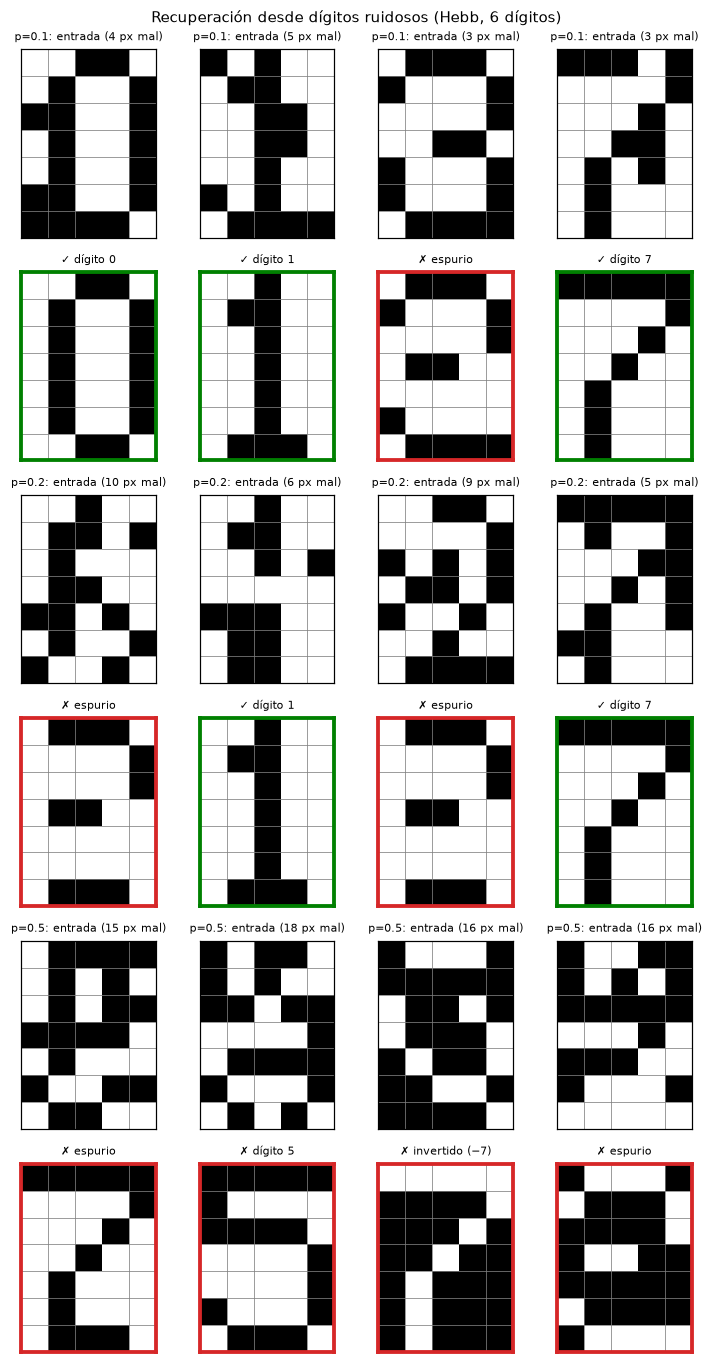

In [17]:
mostrar = [0, 1, 2, 7]
ps_ej = [0.1, 0.2, 0.5]
W, dig = memorias["Hebb, 6 dígitos"]
fig, axs = plt.subplots(2 * len(ps_ej), len(mostrar) * 1, figsize=(1.7 * len(mostrar), 2.1 * 2 * len(ps_ej)))
for r, p in enumerate(ps_ej):
    for c, d in enumerate(mostrar):
        s0 = ruido(X6[d].astype(float), p, rng); sf, nb, _ = recuperar(W, s0, rng)
        dd, cat = clasificar_salida(sf, dig)
        ok = np.array_equal(sf, X6[d])
        dibujar(axs[2 * r, c], s0, forma6, f"p={p}: entrada ({int((s0 != X6[d]).sum())} px mal)", fs=7)
        dibujar(axs[2 * r + 1, c], sf, forma6, ("✓ " if ok else "✗ ") + (f"dígito {dd}" if cat == "otro dígito" else (f"invertido (−{dd})" if cat == "invertido" else cat)),
                color_borde="green" if ok else "tab:red", fs=7)
plt.suptitle("Recuperación desde dígitos ruidosos (Hebb, 6 dígitos)", fontsize=10); plt.tight_layout(); plt.show()

**Observaciones.**

- Con $p=0.1$ (3 a 5 píxeles invertidos de 35) la red repara correctamente los dígitos 0, 1 y 7; el 2 termina en un estado espurio.
- Con $p=0.2$ (5 a 10 píxeles mal) los dígitos 1 y 7 se recuperan, y el 0 y el 2 caen en estados espurios.
- Con $p=0.5$ ningún dígito se recupera: las entradas (de 15 a 18 píxeles invertidos de 35, o sea cerca de la mitad) son nubes de píxeles sin parecido al dígito y las salidas son estados espurios, otro dígito (aquí un 5) o el inverso de un dígito (aquí $-7$).
- Los dos tipos de fallas son distintos. Una salida **espuria** es una imagen "mezclada" que no corresponde a ninguna memoria; una salida **invertida** es una memoria legítima con los colores cambiados.

,"Hebb, 6 dígitos","Hebb, 10 dígitos","Pseudoinversa, 10 dígitos"
p,,,
0.00,1.00,0.0,1.00
0.05,0.91,0.0,0.93
0.10,0.84,0.0,0.81
0.15,0.77,0.0,0.65
0.20,0.64,0.0,0.51
0.25,0.54,0.0,0.33
0.30,0.41,0.0,0.23
0.35,0.22,0.0,0.13
0.40,0.15,0.0,0.07


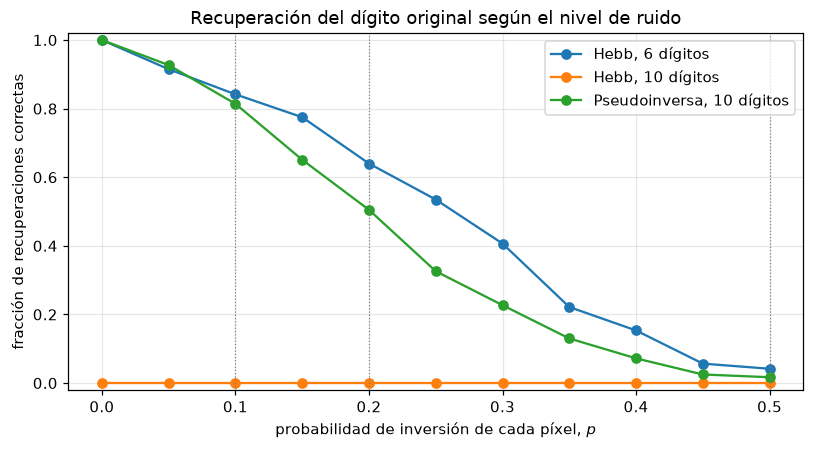

In [18]:
# Tasa de recuperación correcta en función de p para las tres memorias
ps_f = np.round(np.arange(0.0, 0.51, 0.05), 2)
TF = 100
curvas = {}
for nombre, (W, dig) in memorias.items():
    curvas[nombre] = [experimento(W, dig, p, TF, rng)["correcto"].mean() for p in ps_f]

display(pd.DataFrame(curvas, index=pd.Index(ps_f, name="p")).round(2))
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for nombre, c in curvas.items():
    ax.plot(ps_f, c, "o-", label=nombre)
for p in (0.1, 0.2, 0.5):
    ax.axvline(p, color="gray", ls=":", lw=0.8)
ax.set(xlabel="probabilidad de inversión de cada píxel, $p$", ylabel="fracción de recuperaciones correctas",
       title="Recuperación del dígito original según el nivel de ruido", ylim=(-0.02, 1.02)); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Observaciones.**

- **Hebb con 10 dígitos** vale $0$ en toda la curva, incluso para $p=0$ (la entrada sin ruido).
- **Hebb con 6 dígitos** parte de 1 y decae gradualmente: $0.91$ con $p=0.05$, $0.84$ con $0.10$, $0.64$ con $0.20$, $0.41$ con $0.30$ y $\approx0.05$ con $p\ge0.45$. Con 35 píxeles, $p=0.2$ equivale a unos 7 píxeles erróneos, y la red todavía recupera 2 de cada 3 dígitos.
- **Pseudoinversa con 10 dígitos** es parecida para ruido muy bajo ($0.93$ con $p=0.05$ y $0.81$ con $0.10$) pero decae más rápido ($0.51$ con $p=0.2$, $0.23$ con $0.3$). No es una comparación del todo pareja, porque almacena 10 patrones y no 6: con más memorias las cuencas de atracción son más chicas.
- **Incertidumbre:** cada punto promedia 600 corridas (Hebb de 6 dígitos) o 1000 (10 dígitos), por lo que tiene un error estándar de hasta unos $\pm2$ puntos; las diferencias de pocos puntos (por ejemplo, para $p\le0.1$) no son significativas.
- **Hacia $p=0.5$** todas las curvas tienden a 0: la entrada se vuelve independiente del patrón.

---
## 6. Conclusiones

1. **Modelo y entrenamiento.** La red de Hopfield con regla de Hebb es de **un solo paso** ($\mathbf{W}=\frac1N\sum_\mu\xi^\mu\xi^{\mu\top}$, diagonal nula). La dinámica asincrónica disminuye la energía $E=-\tfrac12\mathbf{s}^\top\mathbf{W}\mathbf{s}$ en cada cambio, así que **siempre converge** a un mínimo local, que es el estado que "recupera" la red. Esto se verificó en las simulaciones.
2. **Simetría $\pm\xi$.** Cada patrón almacenado viene acompañado de su inverso (ambos tienen la misma energía). En los experimentos, las salidas "invertidas" son recuperaciones legítimas de una memoria con los colores cambiados.
3. **Figura 5.** La regla de Hebb solo almacenó 2 de los 3 patrones: **$A$ no es un atractor**, porque es casi idéntico a $-C$ (difiere en un píxel; superposición $-0.92$) y la red lo lleva a $-C$. La búsqueda exhaustiva sobre los $2^{25}$ estados muestra exactamente 4 atractores: $\pm B$ y $\pm C$. Con $M/N=0.12$ se esperaba que cupieran los tres, así que el límite $0.138N$ vale para patrones **no correlacionados**; con patrones correlacionados el ruido cruzado desestabiliza antes.
4. **Figura 6 (dígitos 0 a 9).** Con los 10 dígitos, **ninguno es estable** y la red converge a solo dos estados espurios. Las causas son la carga ($10/35\approx0.29$) y sobre todo la **correlación entre dígitos** (por ejemplo, el 3 y el 8 difieren en 2 píxeles). Una búsqueda exhaustiva muestra que el máximo almacenable con Hebb es **6 dígitos** (4 conjuntos posibles, todos con 4, 5 y 7 y sin 3, 8 ni 9). Con esa memoria, la red recupera los dígitos a partir de versiones degradadas.
5. **Ruido ($p=0.1,0.2,0.5$).** Con la memoria de 6 dígitos, los dígitos correctos se recuperan en el 84 % ($p=0.1$), el 65 % ($p=0.2$) y el 3 % ($p=0.5$) de las corridas. Con $p=0.5$ la entrada no contiene información del dígito y el resultado es esencialmente aleatorio (espurio, otro dígito o inverso). Los fallos son sobre todo estados espurios, y los dígitos más parecidos a otros son los más difíciles de recuperar.
6. **Alternativas.** La regla de la **pseudoinversa** logra almacenar los 10 dígitos (todos estables) con una recuperación del 83 % con $p=0.1$ y 51 % con $p=0.2$, pero a costa de confundir dígitos parecidos entre sí. La limitación de los 10 dígitos es, entonces, de la **regla de Hebb** y no del modelo de Hopfield.